# Engagement 3 — Exploratory Data Analysis

**Client:** GuardianShield Insurance (fictional)
**Engagement:** Claims Severity Prediction
**Notebook:** 01 — EDA
**Author:** Yinka Adebimpe

## Purpose

Understand the structure of the claims dataset before modelling:

1. Distribution of the target (`claim_amount`) — heavily right-skewed
2. Feature profiles by claim type and severity
3. Signals that separate small claims from catastrophic ones
4. Data quality checks

In [1]:
# ============================================
# SETUP
# ============================================

import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "config.py").exists():
            return p
    raise FileNotFoundError("Could not find project root")

PROJECT_ROOT = find_project_root(Path.cwd())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

from config import DB_URL, DB_SCHEMA, IMAGES_DIR

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

engine = create_engine(DB_URL)
print(f"Project root: {PROJECT_ROOT}")
print(f"Schema: {DB_SCHEMA}")

Project root: C:\Users\adebi\OneDrive\Desktop\DataScienceConsultingPortfolio\01_Portfolio-Projects\OkYeahInsight-Analytics\GuardianShield-Insurance\Engagement-3-Customer-Claim-Severity
Schema: claims


In [2]:

claims = pd.read_sql(
    f"SELECT * FROM {DB_SCHEMA}.claims",
    engine,
    parse_dates=["claim_date", "policy_start_date"],
)

print(f"Claims: {len(claims):,}")
print(f"Columns: {list(claims.columns)}")
claims.head()

Claims: 5,063
Columns: ['claim_id', 'customer_id', 'claim_date', 'policy_start_date', 'claim_type', 'policy_type', 'customer_segment', 'customer_age', 'region', 'tenure_months', 'incident_severity', 'police_report_filed', 'witness_present', 'days_to_report', 'prior_claims', 'claim_amount']


,claim_id,customer_id,claim_date,policy_start_date,claim_type,policy_type,customer_segment,customer_age,region,tenure_months,incident_severity,police_report_filed,witness_present,days_to_report,prior_claims,claim_amount
0,CLM-0000001,GS-000001,2022-12-18,2018-11-27,Life critical illness,Life,price_sensitive,29,Scottish Borders,49,Minor,False,False,2,1,14189.74
1,CLM-0000002,GS-000002,2025-08-13,2020-09-02,Home burglary,Home,standard,38,Greater London,59,Minor,True,False,1,0,500.49
2,CLM-0000003,GS-000003,2021-12-25,2021-09-25,Motor collision,Motor,loyal,36,Cheshire,3,Moderate,True,False,3,0,1018.65
3,CLM-0000004,GS-000004,2024-04-10,2021-06-29,Motor collision,Motor,standard,60,Tyne and Wear,34,Moderate,False,False,3,2,1863.29
4,CLM-0000005,GS-000005,2025-05-08,2021-03-08,Motor theft,Motor,loyal,18,South Yorkshire,50,Moderate,True,False,1,0,5766.62


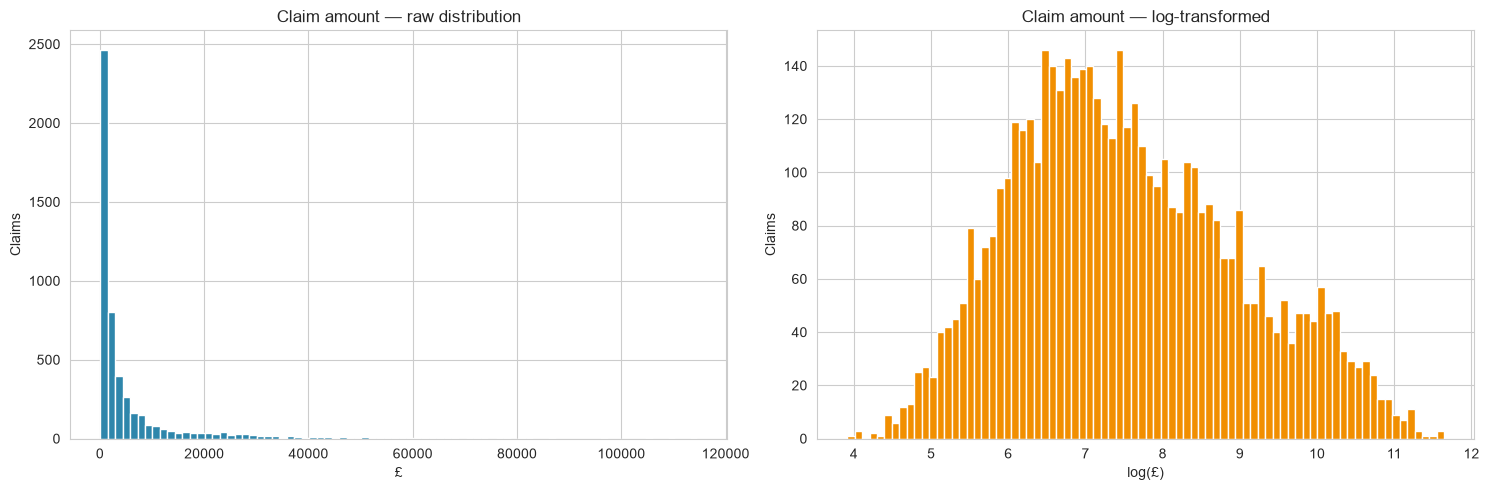

Raw stats (£):
count      5063.00
mean       5562.46
std       10507.98
min          50.00
25%         630.14
50%        1556.25
75%        4993.56
90%       16158.54
95%       27073.82
99%       52755.54
max      114601.31
Name: claim_amount, dtype: float64


In [3]:
# ============================================
# TARGET DISTRIBUTION
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(claims["claim_amount"], bins=80, color="#2E86AB", edgecolor="white")
axes[0].set_title("Claim amount — raw distribution")
axes[0].set_xlabel("£")
axes[0].set_ylabel("Claims")

axes[1].hist(np.log(claims["claim_amount"]), bins=80, color="#F18F01", edgecolor="white")
axes[1].set_title("Claim amount — log-transformed")
axes[1].set_xlabel("log(£)")
axes[1].set_ylabel("Claims")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Raw stats (£):")
print(claims["claim_amount"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(2))

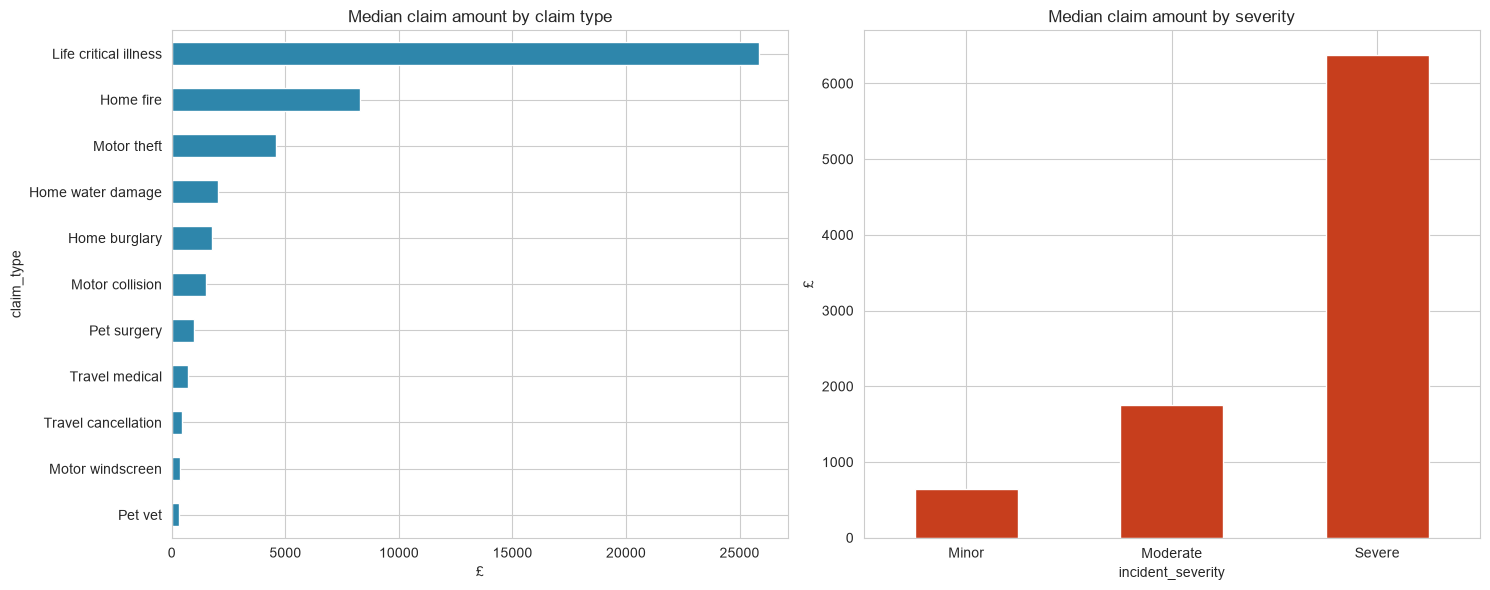

In [4]:
# ============================================
# CLAIMS BY TYPE AND SEVERITY
# ============================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

claims.groupby("claim_type")["claim_amount"].median().sort_values().plot(
    kind="barh", ax=axes[0], color="#2E86AB"
)
axes[0].set_title("Median claim amount by claim type")
axes[0].set_xlabel("£")

claims.groupby("incident_severity")["claim_amount"].median().sort_values().plot(
    kind="bar", ax=axes[1], color="#C73E1D"
)
axes[1].set_title("Median claim amount by severity")
axes[1].set_ylabel("£")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.savefig(IMAGES_DIR / "claims_by_type_severity.png", dpi=150, bbox_inches="tight")
plt.show()

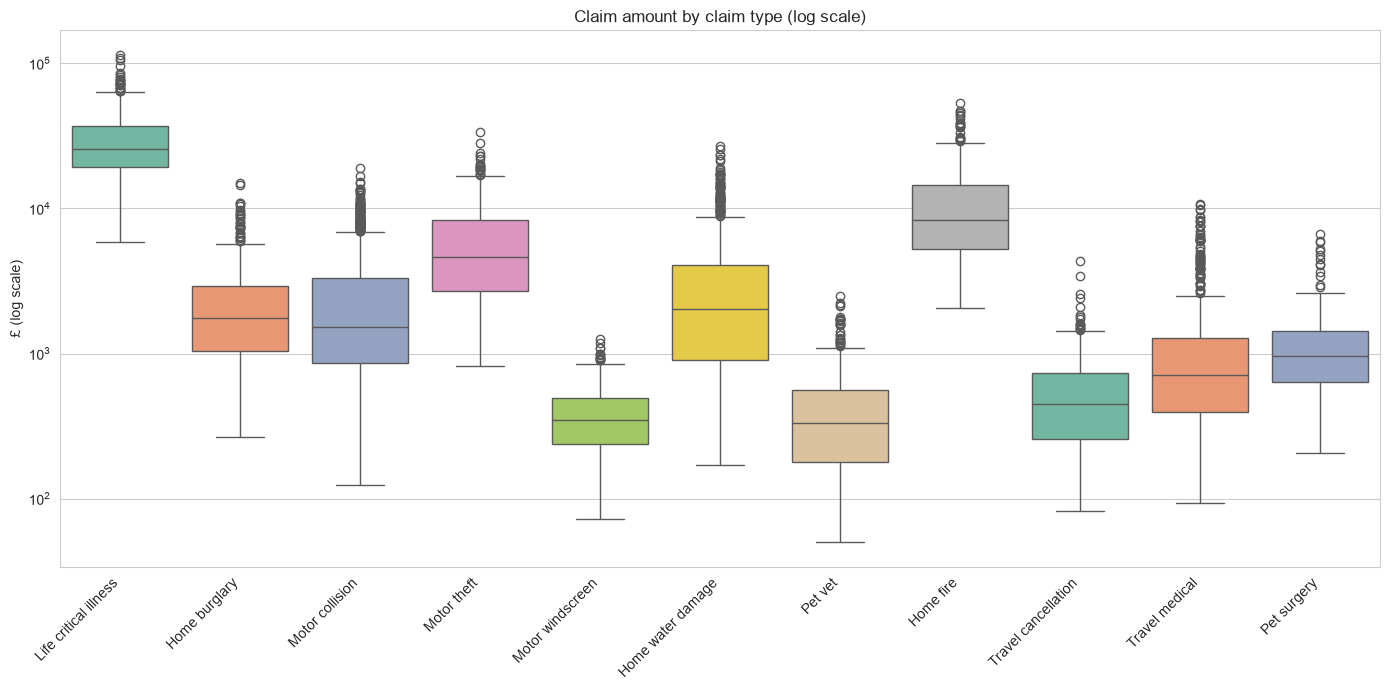

In [5]:
# ============================================
# LOG-SCALE BOXPLOTS
# ============================================

fig, ax = plt.subplots(figsize=(14, 7))

sns.boxplot(
    data=claims,
    x="claim_type",
    y="claim_amount",
    ax=ax,
    hue="claim_type",
    palette="Set2",
    legend=False,
)
ax.set_yscale("log")
ax.set_title("Claim amount by claim type (log scale)")
ax.set_ylabel("£ (log scale)")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig(IMAGES_DIR / "claim_amount_by_type_log.png", dpi=150, bbox_inches="tight")
plt.show()

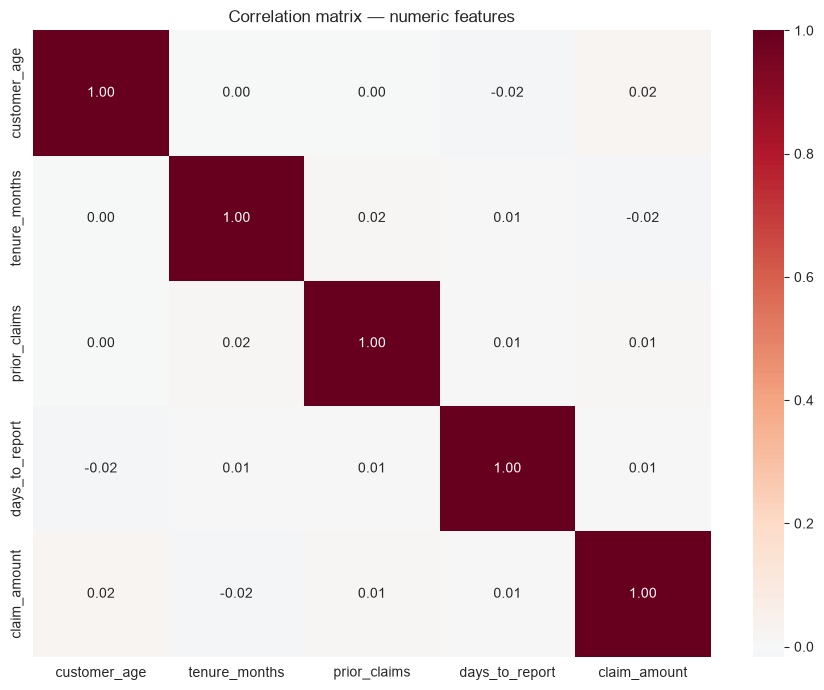


Correlation with claim_amount (sorted by absolute value):
customer_age      0.023
tenure_months    -0.015
prior_claims      0.012
days_to_report    0.007
Name: claim_amount, dtype: float64


In [6]:
# ============================================
# CORRELATION
# ============================================

numeric_cols = [
    "customer_age", "tenure_months", "prior_claims",
    "days_to_report", "claim_amount"
]

corr = claims[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlation matrix — numeric features")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nCorrelation with claim_amount (sorted by absolute value):")
print(
    corr["claim_amount"]
    .drop("claim_amount")
    .sort_values(key=abs, ascending=False)
    .round(3)
)

## Key Insights

### 1. Heavily right-skewed target
- Median: £1,556 | Mean: £5,562 (3.6× median)
- Range: £50 → £114,601
- **Log-transform is essential** — the log distribution is approximately normal

### 2. Claim type dominates severity
| Claim type | Median |
|-----------|--------|
| Life critical illness | £25,853 |
| Home fire | £8,301 |
| Motor theft | £4,597 |
| Motor collision | £1,516 |
| Pet vet | £330 |
| Motor windscreen | £349 |

**77× spread** between the highest and lowest median claim types.

### 3. Severity adds multiplicative signal
Minor £600 → Moderate £1,750 → Severe £6,400
Each level is roughly **3× the previous**.

### 4. Numeric features do not predict severity
Correlation with `claim_amount`:
| Feature | Correlation |
|---------|-------------|
| `customer_age` | 0.023 |
| `tenure_months` | −0.015 |
| `prior_claims` | 0.012 |
| `days_to_report` | 0.007 |

**All below 0.03.** Signal comes from categorical features (`claim_type`, `incident_severity`), not customer profile.

### 5. Business interpretation
Risk is a **product attribute**, not a customer attribute. Pricing and reserving should be structured around claim type and incident severity — customer demographics add almost nothing to claims prediction.

### 6. Next steps
- Feature engineering: log-transform target, encode categoricals, add derived flags
- Modelling: Linear Regression (on log-target), Random Forest, Gradient Boosting
- Metrics: MAE (£), RMSE (£), R² on log scale